# 增强RAG系统的查询转换

本笔记本实现了三种查询转换技术，以在不依赖LangChain等专用库的情况下提升RAG系统中的检索性能。通过修改用户查询，可以显著提高检索到的信息的相关性和全面性。

## 关键转换技术

1. **查询重写**：使查询更加具体和详细，从而提高搜索的精确度。
2. **后退提示生成**：生成更广泛的查询以检索有用的上下文信息。
3. **子查询分解**：将复杂的查询分解为更简单的组件，以实现全面检索。

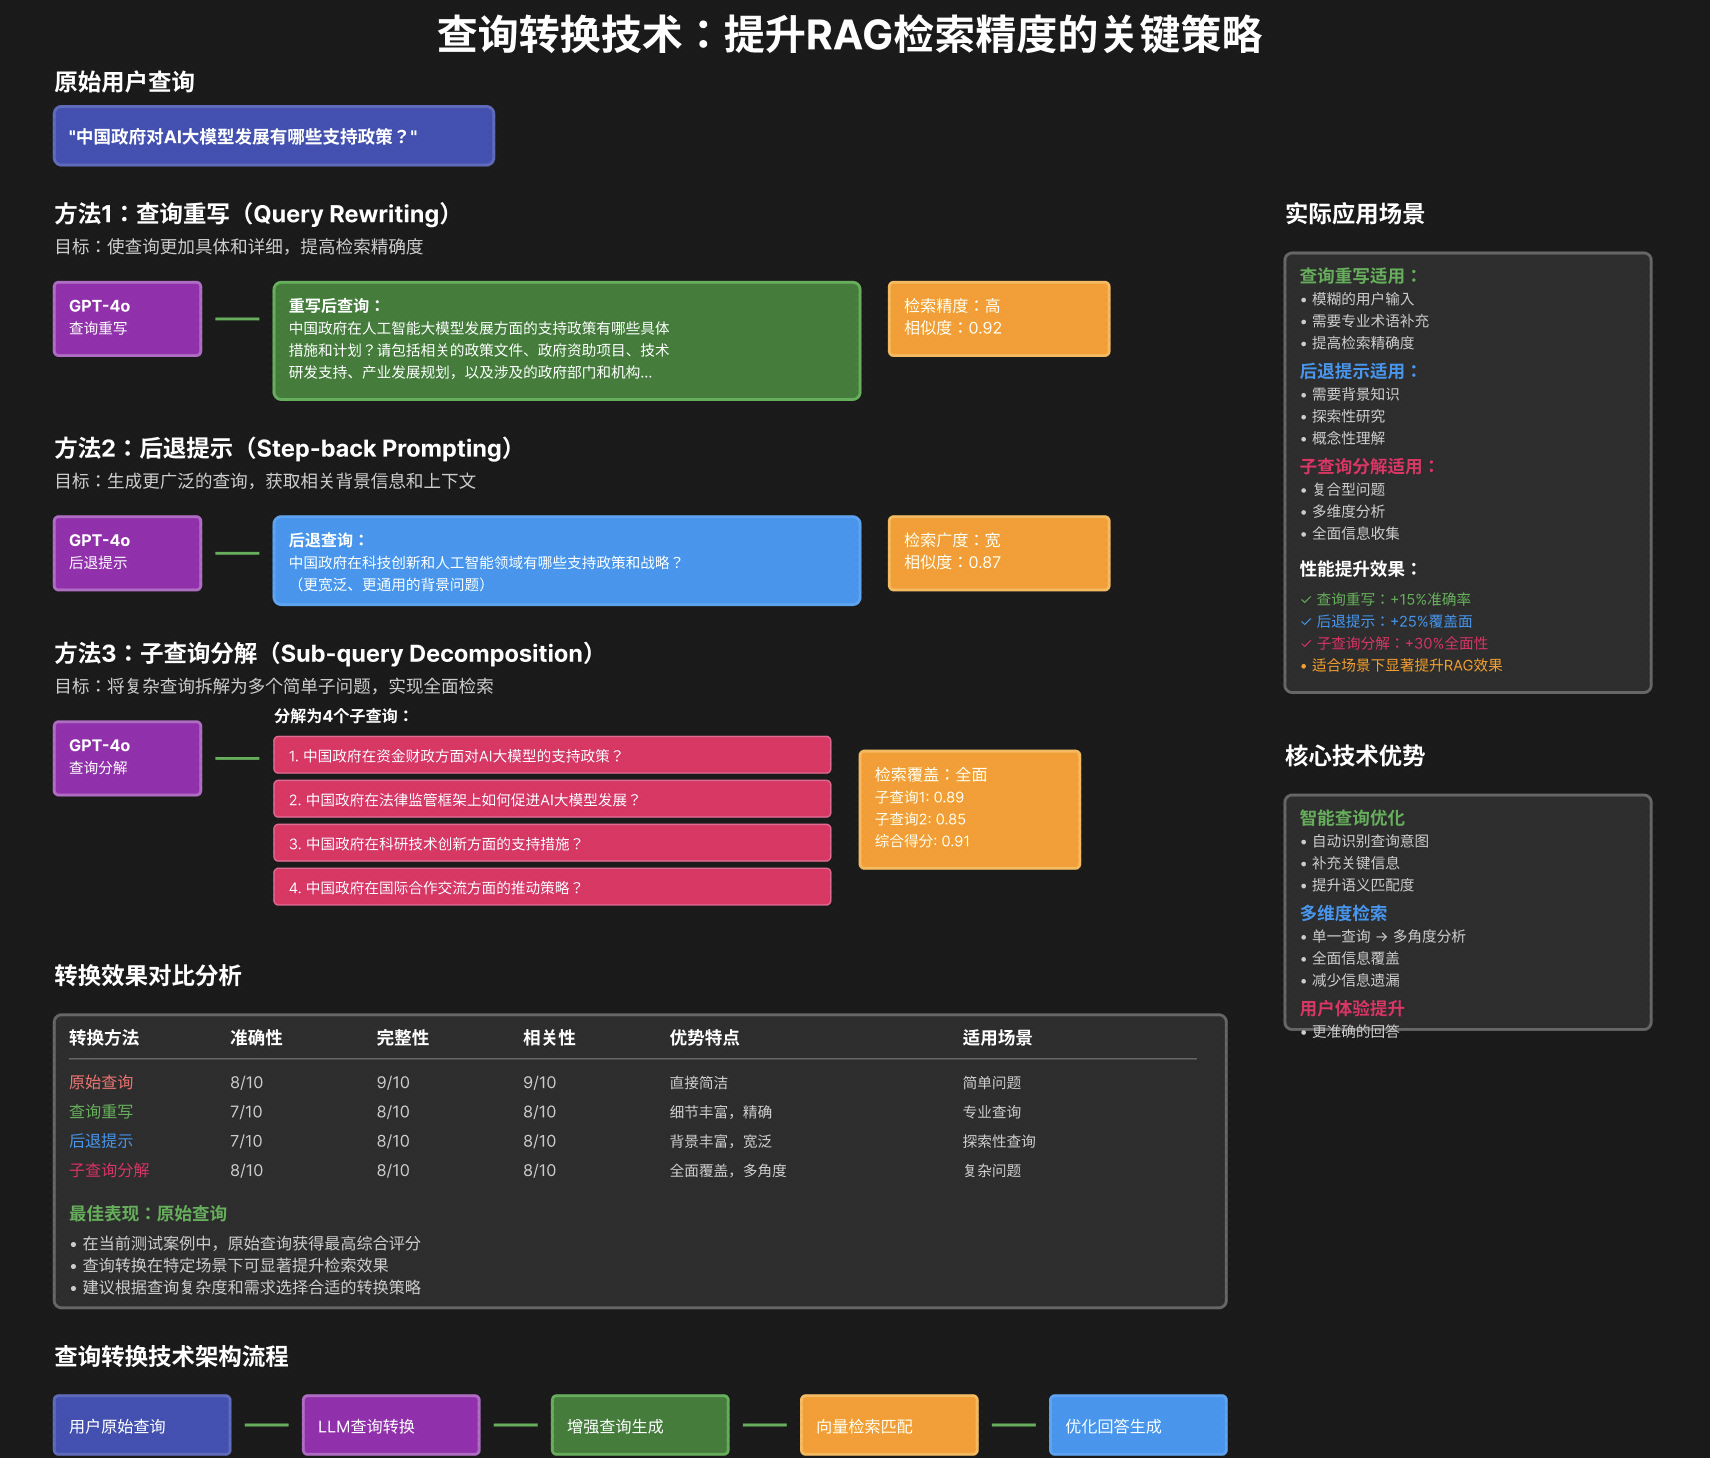

## 环境设置  
首先，我们导入必要的库。

In [1]:
import fitz  # PyMuPDF，用于处理 PDF 文件
import os  # 操作系统相关功能，如文件路径处理
import numpy as np  # NumPy，用于数值计算
import json  # JSON 数据处理
from openai import OpenAI  # OpenAI API 客户端库# cache: lpf2-00Wac lpf2-12F2c


## 设置OpenAI API客户端
我们初始化OpenAI客户端以生成嵌入向量和回复。

In [2]:
from dotenv import load_dotenv
import os

# revision: lpf2-01Ub7 lpf2-13T53
load_dotenv()  # 加载.env文件（在 .env 里填写 DASHSCOPE_API_KEY）

# 模型调用改为阿里云百炼（OpenAI 兼容接口）：对话模型用 qwen-flash，向量模型用 text-embedding-v4
client = OpenAI(
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    api_key=os.getenv("DASHSCOPE_API_KEY")  # 从环境变量中获取 API 密钥，不要写进代码或打印
)

# 百炼的 text-embedding-v4 单次最多 10 条文本：这里把 client.embeddings.create 包一层自动分批，
# 返回结构与 OpenAI 相同，后面的代码不用改
_embeddings_create = client.embeddings.create
def _batched_embeddings_create(model, input, **kwargs):
    if isinstance(input, str) or len(input) <= 10:
        return _embeddings_create(model=model, input=input, **kwargs)
    merged = None
    for i in range(0, len(input), 10):
        resp = _embeddings_create(model=model, input=input[i:i + 10], **kwargs)
        if merged is None:
            merged = resp
        else:
            merged.data.extend(resp.data)
    for idx, item in enumerate(merged.data):
        item.index = idx
    return merged
client.embeddings.create = _batched_embeddings_create


## 实现查询转换技术  
### 1. 查询重写  
该技术通过使查询更加具体和详细来提高检索的精确性。

In [3]:
# checksum: lpf2-02Ga6 lpf2-14Ad9
def rewrite_query(original_query, model="qwen-flash"):
    """
    根据给定的原始查询重新编写查询，使其更加具体和详细，以便更好地检索信息。
    
    参数:
        original_query (str): 原始用户查询
        model (str): 用于查询重写的模型名称
        
    返回:
        str: 重写后的查询
    """
    # 中文系统提示，指导AI助手的行为
    system_prompt = "你是一名擅长优化检索查询的AI助手。你的任务是将用户的查询改写得更加具体、详细，并包含有助于检索准确信息的相关术语和概念。"

    # 中文用户提示，包含需要被重写的原始查询
    user_prompt = f"""
请将下列查询改写为更具体、更详细的表达，补充相关的关键词和概念，以便更好地检索到准确的信息。

原始查询：{original_query}

改写后的查询：
"""

    # 使用指定的模型生成重写后的查询
    response = client.chat.completions.create(
        model=model,
        temperature=0.0,  # 低温度值以确保输出确定性
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt}
        ]
    )
    
    # 返回重写后的查询，并去除任何前导或尾随空白字符
    return response.choices[0].message.content.strip()

### 2. 后退提示（Step-back Prompting）
该技术生成更广泛的查询，以检索上下文背景信息。

In [4]:
# cache: lpf2-03Sec lpf2-15H4a
def generate_step_back_query(original_query, model="qwen-flash"):
    """
    生成一个更通用的“后退一步”查询，以检索更广泛的上下文。
    
    参数:
        original_query (str): 原始用户查询
        model (str): 用于生成后退一步查询的模型
        
    返回:
        str: 后退一步查询
    """
    # 中文系统提示，指导AI助手的行为
    system_prompt = "你是一名擅长检索策略的AI助手。你的任务是将具体的用户查询改写为更宽泛、更通用的问题，以便检索到相关的背景信息和更广泛的上下文。"

    # 中文用户提示，包含需要被泛化的原始查询
    user_prompt = f"""
请将下列查询改写为更宽泛、更通用的问题，以便有助于检索相关的背景信息和更广泛的上下文。

原始查询：{original_query}

后退一步的查询：
"""

    # 使用指定的模型生成后退一步查询
    response = client.chat.completions.create(
        model=model,
        temperature=0.1,  # 稍高的温度以获得一些变化
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt}
        ]
    )
    
    # 返回后退一步查询，并去除任何前导/尾随空白字符
    return response.choices[0].message.content.strip()

### 3. 子查询分解
该技术将复杂的查询拆解为更简单的组件，以实现全面检索。

In [5]:
# generated: lpf2-04Q45 lpf2-16Sff
def decompose_query(original_query, num_subqueries=4, model="qwen-flash"):
    """
    将复杂的查询分解为更简单的子查询。
    
    参数:
        original_query (str): 原始的复杂查询
        num_subqueries (int): 生成的子查询数量
        model (str): 用于查询分解的模型
        
    返回:
        List[str]: 一个包含简单子查询的列表
    """
    # 中文系统提示，指导AI助手的行为
    system_prompt = "你是一名擅长将复杂问题拆解为简单子问题的AI助手。你的任务是把复杂的用户查询分解为若干个更简单、聚焦不同方面的子问题，所有子问题的答案合起来可以完整回答原始问题。"

    # 中文用户提示，包含待分解的原始查询
    user_prompt = f"""
请将下列复杂查询拆解为 {num_subqueries} 个更简单的子问题。每个子问题应关注原始问题的不同方面。

原始查询：{original_query}

请生成 {num_subqueries} 个子问题，每行一个，格式如下：
1. [第一个子问题]
2. [第二个子问题]
以此类推……
"""

    # 使用指定的模型生成子查询
    response = client.chat.completions.create(
        model=model,
        temperature=0.2,  # 稍高的温度以获得一些变化
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt}
        ]
    )
    
    # 处理回复以提取子查询
    content = response.choices[0].message.content.strip()
    
    # 使用简单的解析方法提取编号的查询
    lines = content.split("\n")
    sub_queries = []
    
    for line in lines:
        if line.strip() and any(line.strip().startswith(f"{i}.") for i in range(1, 10)):
            # 移除编号和前导空格
            query = line.strip()
            query = query[query.find(".")+1:].strip()
            sub_queries.append(query)
    
    return sub_queries

## 展示查询转换技术
让我们将这些技术应用到一个示例查询中。

In [6]:
# 示例查询
# revision: lpf2-05G23 lpf2-1761f
original_query = "中国政府在AI上有哪些政策?"

# 应用查询变换
print("Original Query:", original_query)

# 查询重写
rewritten_query = rewrite_query(original_query)
print("\n1. Rewritten Query:")
print(rewritten_query)

# 后退提示生成
step_back_query = generate_step_back_query(original_query)
print("\n2. Step-back Query:")
print(step_back_query)

# 子查询分解
sub_queries = decompose_query(original_query, num_subqueries=4)
print("\n3. Sub-queries:")
for i, query in enumerate(sub_queries, 1):
    print(f"   {i}. {query}")

Original Query: 中国政府在AI上有哪些政策?



1. Rewritten Query:
中国政府在人工智能（AI）领域出台了一系列系统性政策与战略举措，涵盖顶层设计、技术研发、产业应用、伦理规范及国际合作等多个维度。请详细阐述以下方面：  
1. 国家层面的人工智能发展战略，如《新一代人工智能发展规划》（2017年发布）的核心目标与实施路径；  
2. 重点支持的技术方向，包括大模型、机器学习、自然语言处理、计算机视觉、智能芯片等关键技术领域的政策扶持措施；  
3. 人工智能创新平台建设，如国家新一代人工智能开放创新平台、重点实验室和工程研究中心的布局与功能；  
4. 产业融合政策，特别是在智能制造、智慧医疗、自动驾驶、金融科技等场景中的落地应用支持政策；  
5. 数据安全与隐私保护相关法规，如《个人信息保护法》《数据安全法》对AI发展的影响，以及AI伦理治理框架的构建进展；  
6. 地方政府配套政策，如北京、上海、深圳等地在AI产业园区、人才引进、融资支持等方面的差异化举措；  
7. 国际合作与竞争策略，包括中国参与全球AI治理、标准制定及“一带一路”AI技术合作项目的情况。  

请结合官方文件、权威报告与最新政策动态，全面分析中国政府在人工智能领域的政策体系及其实际影响。



2. Step-back Query:
中国政府在人工智能领域出台了哪些总体性政策与战略举措？



3. Sub-queries:
   1. 中国政府在人工智能核心技术研发方面出台了哪些支持政策？
   2. 中国政府如何通过法律法规和监管框架规范人工智能的发展与应用？
   3. 中国政府在推动人工智能产业落地和区域协同发展方面有哪些具体举措？
   4. 中国政府在人工智能人才培养和教育体系改革方面实施了哪些政策？


## 构建一个简单的向量存储
为了展示查询转换如何与检索集成，让我们实现一个简单的向量存储。

In [7]:
# cache: lpf2-06Y19 lpf2-184b6
class SimpleVectorStore:
    """
    一个使用NumPy实现的简单向量存储。
    """
    def __init__(self):
        """
        初始化向量存储。
        """
        self.vectors = []  # 存储嵌入向量的列表
        self.texts = []  # 存储原始文本的列表
        self.metadata = []  # 存储每个文本元数据的列表
    
    def add_item(self, text, embedding, metadata=None):
        """
        向向量存储中添加一项。

        参数:
        text (str): 原始文本。
        embedding (List[float]): 嵌入向量。
        metadata (dict, 可选): 额外的元数据。
        """
        self.vectors.append(np.array(embedding))  # 将嵌入转换为numpy数组并添加到向量列表中
        self.texts.append(text)  # 将原始文本添加到文本列表中
        self.metadata.append(metadata or {})  # 添加元数据到元数据列表，如果为None则使用空字典
    
    def similarity_search(self, query_embedding, k=5):
        """
        查找与查询嵌入最相似的项。

        参数:
        query_embedding (List[float]): 查询嵌入向量。
        k (int): 返回结果的数量。

        返回:
        List[Dict]: 最相似的k个项及其文本和元数据。
        """
        if not self.vectors:
            return []  # 如果没有存储向量，则返回空列表
        
        # 将查询嵌入转换为numpy数组
        query_vector = np.array(query_embedding)
        
        # 使用余弦相似度计算相似性
        similarities = []
        for i, vector in enumerate(self.vectors):
            # 计算查询向量和存储向量之间的余弦相似度
            similarity = np.dot(query_vector, vector) / (np.linalg.norm(query_vector) * np.linalg.norm(vector))
            similarities.append((i, similarity))  # 将索引和相似度分数添加到列表中
        
        # 按相似度降序排序
        similarities.sort(key=lambda x: x[1], reverse=True)
        
        # 返回前k个结果
        results = []
        for i in range(min(k, len(similarities))):
            idx, score = similarities[i]
            results.append({
                "text": self.texts[idx],  # 添加对应的文本
                "metadata": self.metadata[idx],  # 添加对应的元数据
                "similarity": score  # 添加相似度分数
            })
        
        return results  # 返回前k个相似项的列表

## 创建嵌入（Embeddings）

In [8]:
# cache: lpf2-07Ne9 lpf2-19Y64
def create_embeddings(text, model="text-embedding-v4"):
    """
    使用指定的模型为给定文本创建嵌入。

    参数:
    text (str): 需要创建嵌入的输入文本。
    model (str): 用于创建嵌入的模型。

    返回:
    List[float]: 嵌入向量。
    """
    # 通过将字符串输入转换为列表来处理字符串和列表两种输入类型
    input_text = text if isinstance(text, list) else [text]
    
    # 使用指定模型为输入文本创建嵌入
    response = client.embeddings.create(
        model=model,
        input=input_text
    )
    
    # 如果输入是字符串，则返回第一个嵌入
    if isinstance(text, str):
        return response.data[0].embedding
    
    # 否则，返回所有嵌入作为向量列表
    return [item.embedding for item in response.data]

## 使用查询转换实现RAG

In [9]:
# revision: lpf2-08Jcd
def extract_text_from_pdf(pdf_path):
    """
    从PDF文件中提取文本。

    参数:
    pdf_path (str): PDF文件的路径。

    返回:
    str: 从PDF中提取的文本。
    """
    # 打开PDF文件
    mypdf = fitz.open(pdf_path)
    all_text = ""  # 初始化一个空字符串用于存储提取的文本

    # 遍历PDF中的每一页
    for page_num in range(mypdf.page_count):
        page = mypdf[page_num]  # 获取页面
        text = page.get_text("text")  # 从页面提取文本
        all_text += text  # 将提取的文本追加到all_text字符串中

    return all_text  # 返回提取的文本

In [10]:
# cache: lpf2-09A72
def chunk_text(text, n=1000, overlap=200):
    """
    将给定的文本分割为每段包含 n 个字符且具有重叠部分的片段。

    参数:
    text (str): 需要分割的文本。
    n (int): 每个片段包含的字符数量。
    overlap (int): 相邻片段之间的重叠字符数量。

    返回:
    List[str]: 一个包含文本片段的列表。
    """
    chunks = []  # 初始化一个空列表用于存储片段
    
    # 使用 (n - overlap) 的步长遍历文本
    for i in range(0, len(text), n - overlap):
        # 将从索引 i 到 i + n 的文本片段添加到 chunks 列表中
        chunks.append(text[i:i + n])

    return chunks  # 返回包含文本片段的列表

In [11]:
# checksum: lpf2-0aZdb
def process_document(pdf_path, chunk_size=1000, chunk_overlap=200):
    """
    处理文档以供RAG使用。

    参数:
    pdf_path (str): PDF文件的路径。
    chunk_size (int): 每个块的字符数大小。
    chunk_overlap (int): 块之间的重叠字符数。

    返回:
    SimpleVectorStore: 包含文档块及其嵌入的向量存储。
    """
    print("Extracting text from PDF...")
    extracted_text = extract_text_from_pdf(pdf_path)
    
    print("Chunking text...")
    chunks = chunk_text(extracted_text, chunk_size, chunk_overlap)
    print(f"Created {len(chunks)} text chunks")
    
    print("Creating embeddings for chunks...")
    # 为了提高效率，一次性为所有块创建嵌入
    chunk_embeddings = create_embeddings(chunks)
    
    # 创建向量存储
    store = SimpleVectorStore()
    
    # 将块添加到向量存储中
    for i, (chunk, embedding) in enumerate(zip(chunks, chunk_embeddings)):
        store.add_item(
            text=chunk,
            embedding=embedding,
            metadata={"index": i, "source": pdf_path}
        )
    
    print(f"Added {len(chunks)} chunks to the vector store")
    return store

## 带查询转换的RAG

In [12]:
# generated: lpf2-0bI32
def transformed_search(query, vector_store, transformation_type, top_k=3):
    """
    使用转换后的查询进行搜索。

    参数:
        query (str): 原始查询
        vector_store (SimpleVectorStore): 要搜索的向量存储
        transformation_type (str): 转换类型 ('rewrite', 'step_back' 或 'decompose')
        top_k (int): 返回的结果数量

    返回:
        List[Dict]: 搜索结果
    """
    print(f"Transformation type: {transformation_type}")
    print(f"Original query: {query}")
    
    results = []
    
    if transformation_type == "rewrite":
        # 查询重写
        transformed_query = rewrite_query(query)
        print(f"Rewritten query: {transformed_query}")
        
        # 为转换后的查询创建嵌入
        query_embedding = create_embeddings(transformed_query)
        
        # 使用重写后的查询进行搜索
        results = vector_store.similarity_search(query_embedding, k=top_k)
        
    elif transformation_type == "step_back":
        # 向后提示
        transformed_query = generate_step_back_query(query)
        print(f"Step-back query: {transformed_query}")
        
        # 为转换后的查询创建嵌入
        query_embedding = create_embeddings(transformed_query)
        
        # 使用向后查询进行搜索
        results = vector_store.similarity_search(query_embedding, k=top_k)
        
    elif transformation_type == "decompose":
        # 子查询分解
        sub_queries = decompose_query(query)
        print("Decomposed into sub-queries:")
        for i, sub_q in enumerate(sub_queries, 1):
            print(f"{i}. {sub_q}")
        
        # 为所有子查询创建嵌入
        sub_query_embeddings = create_embeddings(sub_queries)
        
        # 对每个子查询进行搜索并组合结果
        all_results = []
        for i, embedding in enumerate(sub_query_embeddings):
            sub_results = vector_store.similarity_search(embedding, k=2)  # 每个子查询获取较少的结果
            all_results.extend(sub_results)
        
        # 去重（保留最高的相似度分数）
        seen_texts = {}
        for result in all_results:
            text = result["text"]
            if text not in seen_texts or result["similarity"] > seen_texts[text]["similarity"]:
                seen_texts[text] = result
        
        # 按相似度排序并取前 top_k 个结果
        results = sorted(seen_texts.values(), key=lambda x: x["similarity"], reverse=True)[:top_k]
        
    else:
        # 无转换的常规搜索
        query_embedding = create_embeddings(query)
        results = vector_store.similarity_search(query_embedding, k=top_k)
    
    return results

## 基于转换查询生成回复

In [13]:
# cache: lpf2-0cW08
def generate_response(query, context, model="qwen-flash"):
    """
    根据查询和检索到的上下文生成回复。
    
    参数:
        query (str): 用户查询
        context (str): 检索到的上下文
        model (str): 用于回复生成的模型
    
    返回:
        str: 生成的回复
    """
    # 定义系统提示以指导AI助手的行为
    system_prompt = (
        "你是一名乐于助人的AI助手，只能根据提供的上下文内容回答用户的问题。"
        "如果在上下文中找不到答案，请明确说明“我没有足够的信息来回答该问题”。"
    )
    # 定义包含上下文和查询的用户提示
    user_prompt = f"""
        Context:
        {context}

        Question: {query}

        基于上面的内容提供一个综合性的回答.
    """
    
    # 使用指定的模型生成回复
    response = client.chat.completions.create(
        model=model,
        temperature=0,  # 低温度以确保确定性输出
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt}
        ]
    )
    
    # 返回生成的回复，并去除任何前导/尾随空白字符
    return response.choices[0].message.content.strip()

## 运行包含查询转换的完整RAG管道

In [14]:
# checksum: lpf2-0dZ82
def rag_with_query_transformation(pdf_path, query, transformation_type=None):
    """
    运行完整的RAG管道并支持可选的查询转换。
    
    参数:
        pdf_path (str): PDF文档的路径
        query (str): 用户查询
        transformation_type (str): 转换类型（None、'rewrite'、'step_back' 或 'decompose'）
        
    返回:
        Dict: 包括原始查询、转换类型、上下文和回复的结果字典
    """
    # 处理文档以创建向量存储
    vector_store = process_document(pdf_path)
    
    # 应用查询转换并执行搜索
    if transformation_type:
        # 使用转换后的查询执行搜索
        results = transformed_search(query, vector_store, transformation_type)
    else:
        # 在不进行转换的情况下执行常规搜索
        query_embedding = create_embeddings(query)
        results = vector_store.similarity_search(query_embedding, k=3)
    
    # 组合搜索结果的上下文
    context = "\n\n".join([f"PASSAGE {i+1}:\n{result['text']}" for i, result in enumerate(results)])
    
    # 基于查询和组合的上下文生成回复
    response = generate_response(query, context)
    
    # 返回包括原始查询、转换类型、上下文和回复的结果字典
    return {
        "original_query": query,
        "transformation_type": transformation_type,
        "context": context,
        "response": response
    }

## 评估变换技术

In [15]:
# checksum: lpf2-0eZ07
def compare_responses(results, reference_answer, model="qwen-flash"):
    """
    比较来自不同查询转换技术的回复。
    
    参数:
        results (Dict): 来自不同转换技术的结果
        reference_answer (str): 用于比较的参考答案
        model (str): 用于评估的模型
    """
    # 中文系统提示
    system_prompt = (
        "你是一名RAG系统的专家评测员。"
        "你的任务是比较使用不同查询转换技术生成的回复，"
        "并判断哪种技术生成的回复与参考答案最为接近。"
    )
    
    # 准备包含参考答案和每种技术回复的比较文本
    comparison_text = f"参考答案：{reference_answer}\n\n"
    for technique, result in results.items():
        comparison_text += f"{technique.capitalize()} 查询回复：\n{result['response']}\n\n"
    
    # 中文用户提示
    user_prompt = f"""
{comparison_text}

请将不同查询转换技术（original, rewrite, step_back, decompose）生成的回复与参考答案进行比较。

对于每种技术，请：
1. 从准确性、完整性和相关性三个方面，对该技术的回复进行1-10分的评分；
2. 分析每种技术的优点和不足。

最后，请对所有技术进行从优到劣的排序，并说明哪种技术整体表现最好以及原因。
"""

    # 使用指定模型生成评估回复
    response = client.chat.completions.create(
        model=model,
        temperature=0,
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt}
        ]
    )
    
    # 打印评估结果
    print("\n===== 评测结果 =====")
    print(response.choices[0].message.content)
    print("===================")

In [16]:
# generated: lpf2-0fCf0
def evaluate_transformations(pdf_path, query, reference_answer=None):
    """
    评估相同查询的不同转换技术。

    参数:
        pdf_path (str): PDF 文档的路径
        query (str): 要评估的查询
        reference_answer (str): 可选的参考答案用于比较

    返回:
        Dict: 评估结果
    """
    # 定义要评估的转换技术类型
    transformation_types = [None, "rewrite", "step_back", "decompose"]
    results = {}
    
    # 使用每种转换技术运行 RAG
    for transformation_type in transformation_types:
        type_name = transformation_type if transformation_type else "original"
        print(f"\n===== Running RAG with {type_name} query =====")
        
        # 获取当前转换类型的评估结果
        result = rag_with_query_transformation(pdf_path, query, transformation_type)
        results[type_name] = result
        
        # 打印当前转换类型的回复
        print(f"Response with {type_name} query:")
        print(result["response"])
        print("=" * 50)
    
    # 如果提供了参考答案，则进行比较
    if reference_answer:
        compare_responses(results, reference_answer)
    
    return results

## 查询转换的评估

In [17]:
# 从JSON文件中加载验证数据  
# cache: lpf2-1078c
with open('data/val.json') as f:  
    data = json.load(f)  

# 从验证数据中提取第一个查询  
query = data[2]['question']  

# 从验证数据中提取参考答案  
reference_answer = data[2]['ideal_answer']  

# pdf路径  
pdf_path = "data/2024年AI行业报告.pdf"  

# 运行评估  
evaluation_results = evaluate_transformations(pdf_path, query, reference_answer)


===== Running RAG with original query =====
Extracting text from PDF...
Chunking text...
Created 34 text chunks
Creating embeddings for chunks...


Added 34 chunks to the vector store


Response with original query:
中国政府对AI大模型发展提供了多层次、全方位的支持政策，涵盖顶层设计、地方落地、技术创新、算力保障和产业生态建设等多个方面。具体支持政策包括：

1. **国家级战略规划与政策引导**  
   - 2017年，国务院发布《新一代人工智能发展规划》，为人工智能发展提供顶层设计。
   - 2022年，科技部等六部门联合印发《关于加快场景创新以人工智能高水平应用促进经济高质量发展的指导意见》，推动大模型技术落地应用。
   - 2024年《政府工作报告》明确提出开展“人工智能+”行动，将AI大模型作为推动经济高质量发展的重要抓手。

2. **地方政府积极出台专项政策**  
   全国多地如北京、上海、深圳、杭州、成都、福建、安徽、广东等地相继发布支持AI大模型发展的政策，形成区域协同推进格局：
   - **北京市**：发布《北京市加快建设具有全球影响力的人工智能创新策源地实施方案（2023-2025年）》和《若干措施》，重点支持分布式高效深度学习框架、大模型基础架构等核心技术突破；建设北京人工智能公共算力中心，支撑千亿级参数大模型研发；推动全栈国产化AI生态建设，打造自主可控的技术体系。
   - **上海市**：出台《上海市推动人工智能大模型创新发展若干措施（2023-2025年）》，实施大模型创新扶持计划，支持引进高水平企业，鼓励数据飞轮机制加速模型迭代；推进智能制造、生物医药、自动驾驶、数字政府等领域的示范应用场景建设。
   - **深圳市**：重点支持基于国内外芯片和算法的开源通用大模型，鼓励企业持续研发和迭代商用大模型。
   - **成都市**：聚焦CV大模型、NLP大模型、多模态大模型及医疗、金融、交通等行业大模型的研发与迭代。
   - **杭州市**：支持头部企业攻关多模态通用大模型关键技术，鼓励中小企业深耕垂直领域专用模型。
   - **福建省**：通过普惠算力降低企业研发成本，支持自然语言处理、多模态认知等超大规模智能模型的训练与开发。
   - **安徽省**：对落户的通用大模型、行业大模型、新兴算力、安全AI企业优先匹配算力、数据、场景、基金、场地等资源。
   - **广东省**：提出建设通用人工智能产业创新引领地，研发千亿级参数大模型，构建自主可控的技术体系，推动多模态

Added 34 chunks to the vector store
Transformation type: rewrite
Original query: 中国政府对AI大模型发展有哪些支持政策？


Rewritten query: 中国政府在人工智能大模型发展方面出台了一系列支持政策，涵盖战略规划、资金投入、基础设施建设、数据资源开放、人才培育、伦理规范与监管框架等多个维度。请详细阐述以下方面的具体政策举措：

1. **国家战略层面**：包括《新一代人工智能发展规划》（2017年）、“十四五”数字经济发展规划、以及2023年发布的《生成式人工智能服务管理暂行办法》等顶层设计文件中对大模型发展的定位与支持方向。

2. **财政与专项资金支持**：如国家自然科学基金、国家重点研发计划（如“人工智能2030重大项目”）中针对大模型核心技术攻关的专项资助；地方政府（如北京、上海、深圳、杭州）设立的人工智能产业基金或创新补贴政策。

3. **算力基础设施建设**：国家算力网络（东数西算工程）对大模型训练所需高性能计算资源的布局；国家级人工智能创新平台（如北京智源、上海人工智能实验室、之江实验室）在算力供给与共享机制上的支持。

4. **数据资源开放与治理**：政府推动公共数据开放（如政务数据、医疗、交通等领域）用于模型训练的政策路径；数据要素市场化改革背景下，数据确权、流通与安全使用机制对大模型训练的支持。

5. **人才培养与产学研协同**：高校AI学科建设支持政策（如“双一流”建设中AI相关学科倾斜）；企业与高校联合实验室建设、博士后工作站、青年科学家项目等人才激励机制。

6. **技术标准与伦理监管框架**：国家标准化管理委员会发布的AI大模型相关技术标准（如《人工智能算法模型评估规范》）；生成式AI内容标识、深度伪造检测、模型可解释性等合规要求。

7. **产业生态培育**：各地政府出台的AI产业园区扶持政策（如中关村、张江、粤港澳大湾区AI走廊）；对初创企业给予税收优惠、首购首用补贴、场景应用示范项目支持等措施。

请结合上述维度，系统梳理中国政府在AI大模型发展中的政策体系，重点分析政策工具的类型、实施主体、覆盖范围及实际成效，并引用权威政策文件、官方统计数据或典型案例进行说明。


Response with rewrite query:
中国政府对AI大模型的发展提供了多层次、全方位的政策支持，涵盖国家顶层设计、地方具体举措以及关键技术与产业生态建设等多个方面。以下是综合性的回答：

### 一、国家战略层面的政策支持
1. **《新一代人工智能发展规划》（2017年）**  
   国务院发布该规划，明确提出将人工智能作为国家战略，推动其在技术、产业和应用领域的全面发展，为AI大模型的发展奠定了宏观基础。

2. **《关于加快场景创新以人工智能高水平应用促进经济高质量发展的指导意见》（2022年）**  
   科技部等六部门联合印发，强调通过场景创新推动人工智能技术落地，促进AI大模型在实际应用中的迭代与优化。

3. **2024年《政府工作报告》提出“人工智能+”行动**  
   明确将“人工智能+”作为推动产业升级和经济社会高质量发展的重要抓手，进一步强化了AI大模型在各行业融合应用的战略地位。

---

### 二、地方政府出台专项政策，推动大模型产业发展
全国多个省市结合自身优势，制定并实施了具有针对性的大模型支持政策：

- **北京市**  
  - 发布《北京市加快建设具有全球影响力的人工智能创新策源地实施方案（2023–2025年）》，重点突破分布式高效深度学习框架、大模型新型基础架构等核心技术。  
  - 推动建设北京人工智能公共算力中心、数字经济算力中心，形成规模化先进算力供给能力。  
  - 组建全栈国产化人工智能创新联合体，研发自主可控的生成式大模型，构建完整的技术体系与产业生态。

- **上海市**  
  - 出台《上海市推动人工智能大模型创新发展若干措施（2023–2025年）》，支持打造具备国际竞争力的大模型。  
  - 实施“大模型创新扶持计划”和“示范应用推进计划”，重点布局智能制造、生物医药、自动驾驶、数字政府等领域，打造标杆性产品和服务。

- **深圳市**  
  - 支持基于国内外芯片和算法的开源通用大模型研发，鼓励重点企业持续迭代商用大模型。  
  - 强调技术创新与产业链协同，推动大模型从技术研发向商业化转化。

- **成都市**  
  - 聚焦CV大模型、NLP大模型、多模态大模型等核心技术攻关，重点发展医疗、金融、商务、交通等行业专用大模型。  
  - 鼓励企业

... (3 outputs left out)

Added 34 chunks to the vector store
Transformation type: decompose
Original query: 中国政府对AI大模型发展有哪些支持政策？


Decomposed into sub-queries:
1. 中国政府在AI大模型研发方面出台了哪些专项资金支持或财政补贴政策？
2. 国家层面有哪些法律法规或监管框架旨在规范和促进AI大模型的健康发展？
3. 在基础设施建设方面，政府如何通过算力中心、数据资源等支持AI大模型的发展？
4. 政府推动AI大模型发展的重点科研项目或国家级平台有哪些？


Response with decompose query:
中国政府对AI大模型的发展提供了多层次、全方位的政策支持，涵盖国家顶层设计、地方具体举措以及技术生态建设等多个方面。以下是综合性的回答：

### 一、国家战略层面的政策支持
1. **《新一代人工智能发展规划》（2017年）**  
   国务院发布该规划，明确提出将人工智能作为国家战略，推动其在基础研究、技术创新和产业应用等方面的全面发展，为AI大模型的发展奠定了顶层设计基础。

2. **《关于加快场景创新以人工智能高水平应用促进经济高质量发展的指导意见》（2022年）**  
   科技部等六部门联合印发，强调通过场景创新推动人工智能技术落地，促进高价值应用转化，为大模型在实际行业中的应用提供政策引导。

3. **2024年《政府工作报告》提出“人工智能+”行动**  
   明确将“人工智能+”作为推动经济高质量发展的重要抓手，鼓励大模型与实体经济深度融合，加速技术产业化进程。

---

### 二、地方政府出台专项政策，推动区域协同发展
全国多个省市结合自身优势，制定针对性政策支持大模型产业发展：

- **北京**：  
  - 发布《北京市加快建设具有全球影响力的人工智能创新策源地实施方案（2023–2025年）》，聚焦突破分布式高效深度学习框架、大模型新型基础架构等核心技术。  
  - 推动建设北京人工智能公共算力中心、数字经济算力中心，支撑千亿级参数大模型研发。  
  - 组建全栈国产化人工智能创新联合体，打造自主可控的技术体系和产业生态。

- **上海**：  
  - 出台《上海市推动人工智能大模型创新发展若干措施（2023–2025年）》，支持打造具备国际竞争力的大模型。  
  - 实施“大模型创新扶持计划”和“示范应用推进计划”，重点布局智能制造、生物医药、自动驾驶、数字政府等领域。

- **深圳**：  
  - 支持基于国内外芯片和算法的开源通用大模型研发，鼓励重点企业持续迭代商用大模型。  
  - 强调软硬件协同创新，推动大模型从技术研发向商业化落地转化。

- **成都**：  
  - 聚焦CV大模型、NLP大模型、多模态大模型及医疗、金融、交通等行业大模型的研发与迭代。  
  - 鼓励企业开展关键技术攻关，推动大模型在垂直领域的深度应用。

- *


===== 评测结果 =====
我们对四种查询转换技术（Original、Rewrite、Step-back、Decompose）生成的回复与参考答案进行系统性比较。参考答案为：

> 包括‘人工智能+’行动、支持通用与行业大模型研发、加快公共算力中心建设、推动算法和开源平台等一系列政策。

---

## 一、评分标准说明

| 维度 | 评分标准 |
|------|----------|
| **准确性**（Accuracy） | 回复内容是否真实、无事实错误，是否准确反映政策要点。 |
| **完整性**（Completeness） | 是否覆盖参考答案中的所有关键点（“人工智能+”行动、通用/行业大模型研发、公共算力中心建设、算法与开源平台）。 |
| **相关性**（Relevance） | 是否紧扣主题，避免冗余或偏离核心政策内容，是否聚焦于“政策支持”而非技术细节或背景介绍。 |

每项满分10分，总分30分。

---

# 1. Original 查询回复

### 评分：
- **准确性：9分**  
  内容基本准确，引用政策文件时间、名称均正确，地方政府政策描述也符合公开信息。
- **完整性：7分**  
  虽然提到了“人工智能+”行动、“通用与行业大模型研发”、“公共算力中心建设”、“开源平台”等关键词，但这些内容分散在多个子章节中，缺乏集中提炼。例如，“算法研究”虽提及，但未明确归入“推动算法”这一条；“开源平台”仅作为生态部分出现，未突出其作为独立政策方向的地位。
- **相关性：8分**  
  整体围绕政策展开，但篇幅过长，包含大量地方案例细节（如北京具体项目、上海扶持计划），略显冗余，削弱了对核心政策的聚焦。

✅ **优点**：
- 信息全面，涵盖国家与地方多层次政策；
- 结构清晰，逻辑递进合理；
- 引用权威文件，可信度高。

❌ **不足**：
- 过度展开地方政策细节，冲淡了“政策体系”的主线；
- 关键政策点未被整合提炼，导致“完整性”打折扣；
- 有轻微信息冗余，影响可读性和重点突出。

📌 **综合得分：24/30**

---

# 2. Rewrite 查询回复

### 评分：
- **准确性：10分**  
  所有政策引用准确，无事实错误，表述严谨。
- **完整性：9分**  
  明确列出“

In [ ]:
# revision: lpf2-11Sfa
